# Student project: Where does NEV peak in a Saturn density wave?

**Goal:** Compare the phase of the dominant NEV modulation across BetCen occultations and density waves. The method is an **unweighted first-order sinusoid** fitted to 100-photon-sample-bin Sheppard-corrected NEV. This estimates the phase of the **first harmonic**, which may differ from the highest individual point or the true maximum if the profile is not sinusoidal.

**Instructions:** Change `occstring`, `wavestring`, file directories, and the **four crest guesses** for each analysis. Run from top to bottom. Check the crest plot before accepting any result. The notebook reports approximate bootstrap confidence intervals, but these depend on the sinusoidal model and resampling assumptions; leave-one-cycle-out tests are separate sensitivity checks.


## 1. Choose the occultation and set up the analysis

Import the libraries and specify which **BetCen occultation** and **density wave** to analyze. Set the locations of the data files, the number of samples per NEV bin, and the smoothing width used to identify crests. The wave-region limits are initial selections, not guaranteed boundaries; check them for every new case. **Edit this cell first** when changing datasets.


In [77]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from scipy.io import readsav
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks
from scipy.optimize import minimize_scalar

from matplotlib.ticker import MultipleLocator

# ---------------------------
# OCCULTATION AND DENSITY WAVE
# ---------------------------

occstring = "BetCen_064E" #"BetCen_105I" 
wavestring = "janus54" #"janus54" 

# Change this to the directory on your computer
base_dir = Path(r"D:\\")

bin_directory = base_dir / "Bet Cen 10 km occs"
unbin_directory = base_dir / "Bet Cen unbinned data"

# ---------------------------
# BINNING PARAMETERS
# ---------------------------

bin_pt = 100
step_size = 5

# ---------------------------
# ANALYSIS PARAMETERS
# ---------------------------

# Smoothing width used ONLY to identify density-wave crests
crest_smoothing_km = 0.5

# Optional: reverse radial phase to match a verified
# physical phase convention
reverse_phase = False


# ============================================================
# DENSITY-WAVE CONFIGURATION
# ============================================================
# Select a wave by changing wavestring below.
#
# radial_range: approximate extent of the density wave (km)
# neighboring_range: nearby region outside the wave (km)
# lam_toom: Toomre most-unstable wavelength (m)
#
# These are starting ranges from Table 5.1.
# Always inspect the optical-depth profile and verify the
# selected wave crests before continuing.

wave_config = {
    "janus21": {
        "name": "Janus 2:1",
        "radial_range": (96220, 96420), # 96600),
        "neighboring_range": (94800, 95200),
        "lam_toom": 43.0
    },
    "pandora54": {
        "name": "Pandora 5:4",
        "radial_range": (122320, 122420), #122600),
        "neighboring_range": (122200, 122300),
        "lam_toom": 36.0
    },
    "janus43": {
        "name": "Janus 4:3",
        "radial_range": (125240, 125450), #125560),
        "neighboring_range": (125100, 125200),
        "lam_toom": 68.0
    },
    "janus54": {
        "name": "Janus 5:4",
        "radial_range": (130690, 130860),
        "neighboring_range": (130550, 130650),
        "lam_toom": 55.0
    },
    "mimas53": {
        "name": "Mimas 5:3",
        "radial_range": (132320, 132450),
        "neighboring_range": (132080, 132180),
        "lam_toom": 46.0
    },
    "janus65": {
        "name": "Janus 6:5",
        "radial_range": (134230, 134400),
        "neighboring_range": (134100, 134200),
        "lam_toom": 64.0
    }
}

# ------------------------------------------------------------
# STUDENT SELECTION
# ------------------------------------------------------------

if wavestring not in wave_config:
    raise ValueError(f"Unknown density wave: {wavestring}")

wave = wave_config[wavestring]

wave_str = wave["name"]
wave_range = wave["radial_range"]
neighboring_range = wave["neighboring_range"]
lam_toom = wave["lam_toom"]

print(f"Selected wave: {wave_str}")
print(f"Wave radial range: {wave_range} km")
print(f"Neighboring region: {neighboring_range} km")
print(f"Toomre wavelength: {lam_toom:.1f} m")

wave_str = wave_config[wavestring]["name"]
radlimits = wave_config[wavestring]["radial_range"]

print(f"Occultation: {occstring}")
print(f"Wave: {wave_str}")

Selected wave: Janus 5:4
Wave radial range: (130690, 130860) km
Neighboring region: (130550, 130650) km
Toomre wavelength: 55.0 m
Occultation: BetCen_064E
Wave: Janus 5:4


## 2. Load the occultation data

Read the binned and unbinned Cassini UVIS files and extract the radii, photon counts, sampling areas, and calibration quantities. The later calculations use these arrays to derive optical depth and excess variance. This cell also checks that required inputs exist and have compatible dimensions.


In [78]:
bin_file = bin_directory / f"{occstring}_10km.sav"
unbin_file = unbin_directory / f"{occstring}_data_geom_051623.sav"

if not bin_file.exists():
    raise FileNotFoundError(bin_file)

if not unbin_file.exists():
    raise FileNotFoundError(unbin_file)

binned_data = readsav(str(bin_file))
unbinned_data = readsav(str(unbin_file))

pdsdata = binned_data.pdsdata[0]

radius = np.asarray(unbinned_data.radius, dtype=float).ravel()
data = np.asarray(unbinned_data.data, dtype=float).ravel()
et = np.asarray(unbinned_data.et, dtype=float).ravel()

int_area2 = np.asarray(
    unbinned_data.int_area2, dtype=float
).ravel()

rad10km = np.asarray(pdsdata.radius, dtype=float).ravel()

mu_values = np.asarray(pdsdata.mu, dtype=float).ravel()
i0_values = np.asarray(pdsdata.i0, dtype=float).ravel()
background_values = np.asarray(
    pdsdata.background, dtype=float
).ravel()

mu = float(np.nanmean(mu_values))
i0 = float(np.nanmean(i0_values))
back = float(np.nanmean(background_values))

assert len(radius) == len(data) == len(int_area2)
assert i0 > 0
assert back >= 0
assert 0 < mu <= 1

integration_per = np.abs(et[0] - et[1])*1000.

print("Number of measurements:", len(data))
print("Radius range:", np.nanmin(radius), np.nanmax(radius))
print("I0:", i0)
print("Background:", back)
print("mu:", mu)
print(f"Integration: {integration_per} ms")

Number of measurements: 10301888
Radius range: 84951.62749085332 151166.81144580615
I0: 1260.3485794537378
Background: 0.9382715821266174
mu: 0.9185905886334473
Integration: 1.999974250793457 ms


## 3. Select the wave region and calculate optical depth

Restrict the measurements to the chosen radial range, sort them in outward-increasing radius, and calculate optical depth from the background-subtracted counts. A small count floor prevents taking the logarithm of zero or negative counts. **Why:** all subsequent phase measurements must refer to the same correctly ordered part of the wave.


In [79]:
# Select the wave region
mask = (
    (radius >= radlimits[0]) &
    (radius <= radlimits[1]) &
    np.isfinite(radius) &
    np.isfinite(data) &
    np.isfinite(int_area2)
)

radius_chunk = radius[mask]
data_chunk = data[mask]
area_chunk = int_area2[mask]

# Sort all arrays together by increasing radius
order = np.argsort(radius_chunk)

radius_chunk = radius_chunk[order]
data_chunk = data_chunk[order]
area_chunk = area_chunk[order]

assert len(radius_chunk) > 100
assert np.all(np.diff(radius_chunk) >= 0)

area = float(np.mean(area_chunk))

# Background-subtracted data
I = data_chunk - back

# Detection floor for optical-depth calculation.
# Raw counts per integration: background Poisson sigma ~ sqrt(back).
I_floor = max(np.sqrt(back), 1e-12)

I_used = np.maximum(I, I_floor)

tau = np.log(i0 / I_used)

# Optical depth can be slightly negative because of noise.
# Do not automatically clip it to zero.

print("Selected measurements:", len(radius_chunk))
print("Mean radial spacing (km):",
      np.mean(np.diff(radius_chunk)))
print("Integration area:", area)
print("Optical depth range:", np.min(tau), np.max(tau))
print("Measurements using I floor:",
      np.sum(I <= I_floor))

Selected measurements: 20655
Mean radial spacing (km): 0.008230421245372103
Integration area: 551.8434178651016
Optical depth range: -0.21781402227152713 3.2061083500824057
Measurements using I floor: 0


## 4. Inspect the optical-depth profile

Plot the optical depth against radius, together with a smoothed version used **only to locate wave crests**. Smoothing makes the repeating wave pattern easier to recognize; it is not used to calculate NEV. Identify four successive crests before proceeding to the next cell.


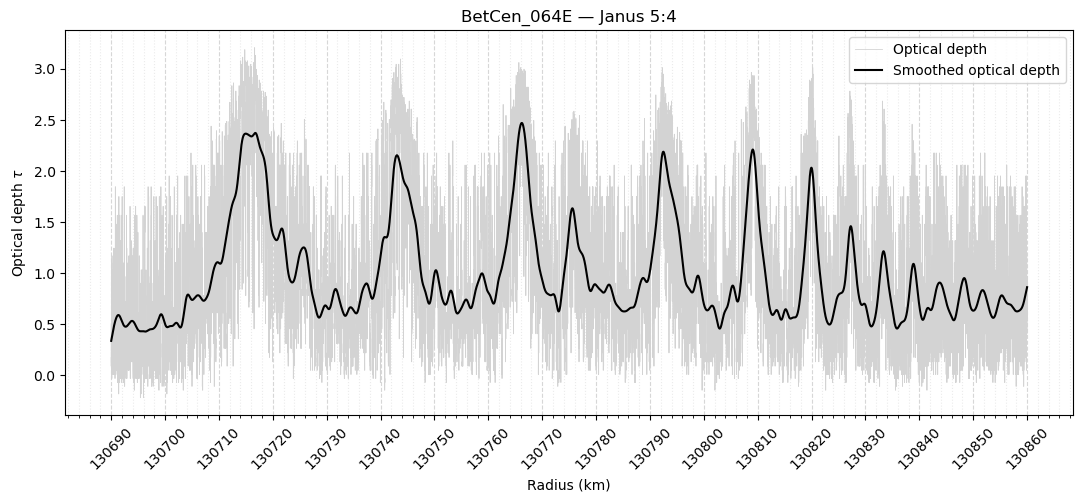

In [80]:
# Smooth only for crest identification
dr = np.median(np.diff(radius_chunk))

sigma_samples = crest_smoothing_km / dr

tau_smooth = gaussian_filter1d(
    tau,
    sigma=sigma_samples,
    mode="nearest"
)

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(radius_chunk, tau, color="lightgray",
        linewidth=0.6, label="Optical depth")

ax.plot(radius_chunk, tau_smooth, color="black",
        linewidth=1.5, label="Smoothed optical depth")

ax.set(
    xlabel="Radius (km)",
    ylabel=r"Optical depth $\tau$",
    title=f"{occstring} — {wave_str}"
)

# More detailed radial axis
ax.xaxis.set_major_locator(MultipleLocator(10))
ax.xaxis.set_minor_locator(MultipleLocator(2))

# Display actual radius values without scientific notation
ax.ticklabel_format(axis="x", style="plain", useOffset=False)

# Gridlines to help estimate crest locations
ax.grid(axis="x", which="major", linestyle="--", alpha=0.5)
ax.grid(axis="x", which="minor", linestyle=":", alpha=0.25)

# Rotate labels slightly if crowded
plt.xticks(rotation=45)

ax.legend()
plt.show()
plt.close()

## Select and verify the crests

Use the optical-depth plot above to identify **four successive crests** of the same wave. Enter approximate radii in increasing order. The code refines each guess within ±3 km; inspect the resulting plot. **Do not reuse crest guesses from another occultation or wave without checking.**


## 5. Refine and verify four wave crests

Enter approximate radii of **four consecutive density-wave crests**. The program searches near each guess for a local maximum in the smoothed optical-depth profile, then displays the selected positions for inspection. Four crests define **three complete crest-to-crest cycles**. If any marker lands on the wrong feature, revise the guesses and rerun this cell.


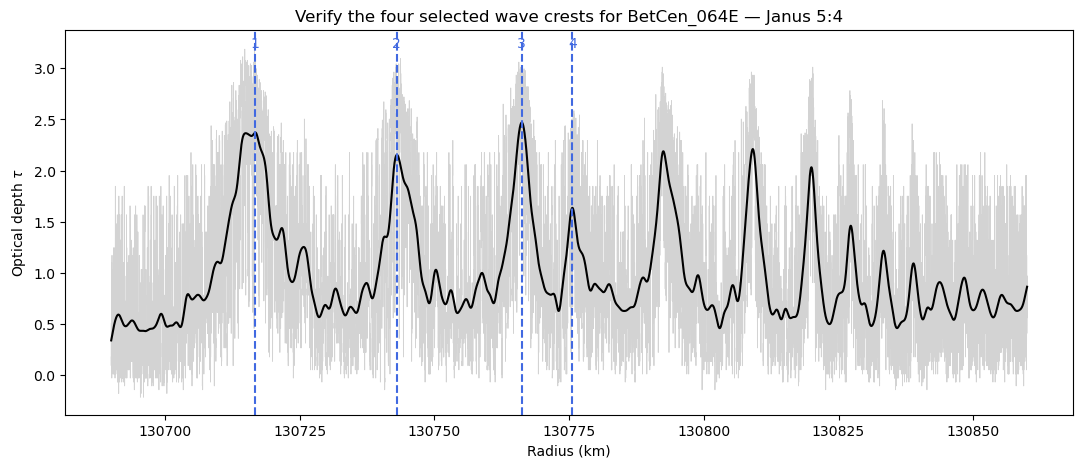

Selected crests: [130716.75170103 130743.0329175  130766.20648435 130775.59676496]
Wavelengths between crests (km): [26.28121647 23.17356685  9.39028061]


In [81]:
# ENTER FOUR APPROXIMATE CREST RADII (km)
# These must be in increasing radial order.

# IMPORTANT: The automatic guesses are for BetCen_064E Janus 5:4 only.
# Review and update for any other occultation or density wave.
# EDIT these for every occultation and wave.

crest_guesses = np.array([130715.0,  # First crest
                          130743.0,  # Second crest
                          130765.0,  # Third crest
                          130775.0]) # Fourth crest

# Search within +/- this distance of each guess
search_half_width_km = 3.0

peakmids = []

for guess in crest_guesses:

    nearby = (
        (radius_chunk >= guess - search_half_width_km) &
        (radius_chunk <= guess + search_half_width_km)
    )

    if not np.any(nearby):
        raise ValueError(f"No data near crest guess {guess}")

    local_radius = radius_chunk[nearby]
    local_tau = tau_smooth[nearby]

    peak_radius = local_radius[np.argmax(local_tau)]
    peakmids.append(peak_radius)

peakmids = np.asarray(peakmids)

assert len(peakmids) >= 2
assert np.all(np.diff(peakmids) > 0)

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(radius_chunk, tau, color="lightgray", linewidth=0.6)
ax.plot(radius_chunk, tau_smooth, color="black")

for j, crest in enumerate(peakmids):
    ax.axvline(crest, color="royalblue", linestyle="--")
    ax.text(crest, ax.get_ylim()[1] * 0.95,
            str(j + 1), ha="center", color="royalblue")

ax.set(
    xlabel="Radius (km)",
    ylabel=r"Optical depth $\tau$",
    title="Verify the four selected wave crests for "+ f"{occstring} — {wave_str}"
)

ax.ticklabel_format(axis="x", style="plain", useOffset=False)
plt.show()

print("Selected crests:", peakmids)
print("Wavelengths between crests (km):", np.diff(peakmids))

# Number of complete crest-to-crest intervals for this selection
n_cycles = len(peakmids) - 1
assert n_cycles >= 1


## Calculate NEV in 100-sample bins

The code below retains the baseline notebook's NEV normalization and Sheppard correction. It assigns phase 0° at each selected crest and 360° at the next crest, increasing outward.


## 6. Measure excess variance and assign radial phase

Divide each selected crest-to-crest interval into **100-sample bins** and calculate the Sheppard-corrected normalized excess variance (NEV), average optical depth, and representative radius of each bin. Assign a radial phase running from **0° at one crest to 360° at the next**. Retain cycle labels so that later tests can examine whether one cycle dominates the result.


In [82]:
radmiddles = []
nevvals = []
nevshep = []
tauvals = []
phases = []
bin_cycles = []

bin_radial_widths = []

for cycle in range(len(peakmids) - 1):

    r1 = peakmids[cycle]
    r2 = peakmids[cycle + 1]

    selected = (
        (radius_chunk >= r1) &
        (radius_chunk < r2)
    )

    r = radius_chunk[selected]
    d = data_chunk[selected]
    t = tau[selected]

    n_full, remainder = divmod(len(d), bin_pt)

    if n_full < 1:
        raise ValueError(
            f"Undulation {cycle + 1} has fewer than {bin_pt} samples"
        )

    left_trim = remainder // 2
    stop = left_trim + n_full * bin_pt

    r = r[left_trim:stop]
    d = d[left_trim:stop]
    t = t[left_trim:stop]

    print(
        f"Undulation {cycle + 1}: "
        f"{n_full} bins of {bin_pt} measurements; "
        f"{remainder} measurements excluded"
    )

    for start in range(0, len(d), bin_pt):

        end = start + bin_pt

        rb = r[start:end]
        db = d[start:end]
        tb = t[start:end]

        assert len(db) == bin_pt

        mean_count = np.mean(db)
        variance = np.var(db, ddof=0)

        # Original normalized excess variance
        nev = (variance - mean_count) / i0**2

        mean_tau = np.mean(tb)

        # Sheppard correction from original notebook
        sheppard = np.exp(-mean_tau) / (12.0 * i0)

        nev_corrected = nev - sheppard

        radius_mid = np.median(rb)

        phase = (
            360.0 * (radius_mid - r1) / (r2 - r1)
        )

        radmiddles.append(radius_mid)
        nevvals.append(nev)
        nevshep.append(nev_corrected)
        tauvals.append(mean_tau)
        phases.append(phase)
        bin_cycles.append(cycle)

        bin_radial_widths.append(rb[-1] - rb[0])

radmiddles = np.asarray(radmiddles)
nevvals = np.asarray(nevvals)
nevshep = np.asarray(nevshep)
tauvals = np.asarray(tauvals)
phases = np.asarray(phases)
bin_cycles = np.asarray(bin_cycles)
bin_radial_widths = np.asarray(bin_radial_widths)

assert len(phases) == len(nevshep) == len(radmiddles)
assert np.all((phases >= 0) & (phases < 360))

print("\nTotal 100-point bins:", len(nevshep))
print("Median bin width (km):", np.median(bin_radial_widths))
print("NEV range:", np.min(nevshep), np.max(nevshep))

# ============================================================
# PRESERVE FIRST-STAGE ARRAYS FOR ALL SUBSEQUENT ANALYSES
# ============================================================

phase_radial = np.asarray(phases, dtype=float).copy()
nev_first = np.asarray(nevshep, dtype=float).copy()
cycle_first = np.asarray(bin_cycles, dtype=int).copy()
radius_first = np.asarray(radmiddles, dtype=float).copy()

# Reverse phase convention, if needed for interpretation
phase_reversed = (-phase_radial) % 360.0

# Check alignment
assert (
    len(phase_radial)
    == len(nev_first)
    == len(cycle_first)
    == len(radius_first)
), "First-stage arrays are not aligned."

print(f"First-stage bins: {len(phase_radial)}")

Undulation 1: 31 bins of 100 measurements; 94 measurements excluded
Undulation 2: 28 bins of 100 measurements; 16 measurements excluded
Undulation 3: 11 bins of 100 measurements; 41 measurements excluded

Total 100-point bins: 70
Median bin width (km): 0.8146647149478667
NEV range: 0.003928383408265038 0.09283824588337067
First-stage bins: 70


## Fit the dominant sinusoidal modulation

The fit is `NEV = C + A cos(phase - phase_max)`, with `A ≥ 0`. The **radial phase of the maximum** is `phase_max`; the **crest-referenced reversed-phase offset** is `(360 - phase_max) % 360`. These are geometric conventions, not a demonstrated physical wake-growth delay.


## 7. Fit the first-harmonic NEV modulation and estimate uncertainty

Fit an **unweighted single sinusoid** to NEV as a function of radial phase. Its amplitude measures the size of the first-harmonic variation, and its fitted maximum provides a reproducible phase estimate even when individual points are scattered. Convert that maximum to a crest-referenced reversed-phase offset. The code uses **2,000 moving-block residual bootstrap realizations** to estimate approximate 95% intervals for amplitude and phase, then plots the result. These intervals are conditional on the sinusoidal model and resampling assumptions.


Occultation: BetCen_064E
Density wave: Janus 5:4

Amplitude = 0.011354 (95% CI: 0.005657 to 0.017657)
Radial maximum = 250.60 deg (95% CI: 217.59 to 285.60)
Crest-referenced offset = 109.40 deg (95% CI: 74.40 to 142.41)


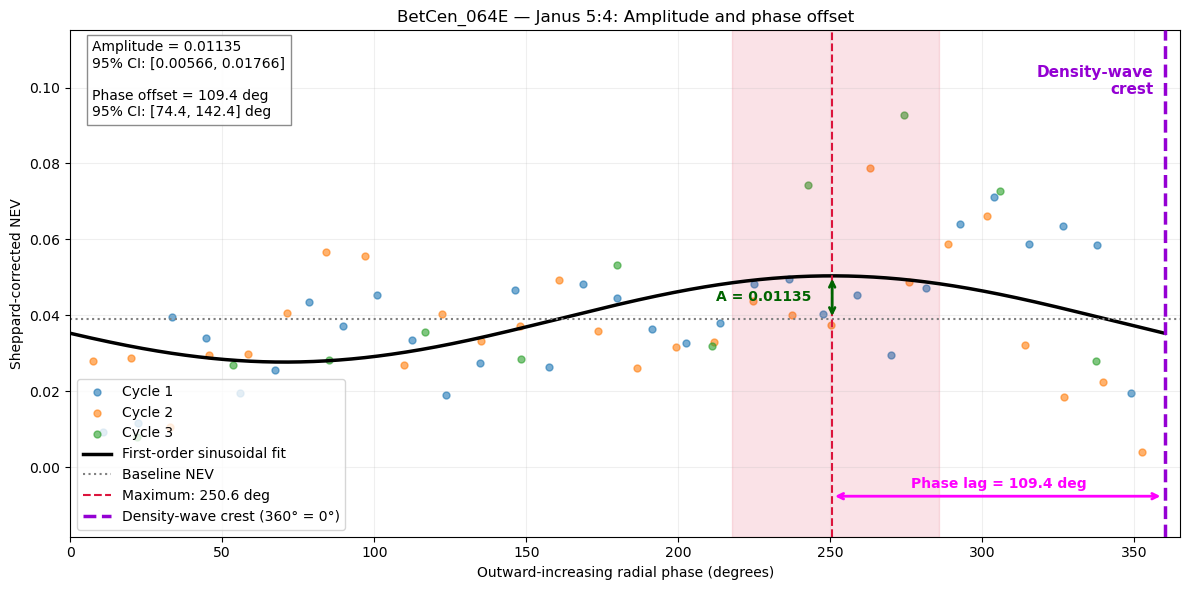

In [83]:
# ============================================================
# FIRST-ORDER SINUSOID WITH AMPLITUDE AND PHASE 95% CIs
# ============================================================

def fit_sinusoid(phase_deg, nev):
    phase_deg = np.asarray(phase_deg, dtype=float)
    nev = np.asarray(nev, dtype=float)

    theta = np.deg2rad(phase_deg)
    X = np.column_stack([
        np.ones(len(theta)),
        np.cos(theta),
        np.sin(theta)
    ])

    if len(nev) < 6 or np.linalg.matrix_rank(X) < 3:
        raise ValueError("Insufficient data for sinusoidal fit.")

    C, a, b = np.linalg.lstsq(X, nev, rcond=None)[0]
    A = np.hypot(a, b)
    phase_max = np.degrees(np.arctan2(b, a)) % 360

    return {
        "C": C, "a": a, "b": b,
        "A": A,
        "phase_max": phase_max,
        "crest_offset": (-phase_max) % 360
    }


def circular_difference(angle, reference):
    return ((np.asarray(angle) - reference + 180) % 360) - 180


def moving_block_resample(values, length, rng):
    n = len(values)
    starts = rng.integers(0, n, size=int(np.ceil(n / length)))
    indices = np.concatenate([
        (start + np.arange(length)) % n for start in starts
    ])[:n]
    return np.asarray(values)[indices]


# ------------------------------------------------------------
# Fit the observed first-stage NEV
# ------------------------------------------------------------

valid = np.isfinite(phase_radial) & np.isfinite(nev_first)

fit_phase = np.asarray(phase_radial)[valid]
fit_nev = np.asarray(nev_first)[valid]
fit_cycle = np.asarray(cycle_first)[valid]

result = fit_sinusoid(fit_phase, fit_nev)

theta = np.deg2rad(fit_phase)
prediction = (
    result["C"]
    + result["a"] * np.cos(theta)
    + result["b"] * np.sin(theta)
)

residuals = fit_nev - prediction

# ------------------------------------------------------------
# Moving-block residual bootstrap
# ------------------------------------------------------------

n_boot = 2000
block_length = 3
rng = np.random.default_rng(2026)

boot_amplitudes = np.empty(n_boot)
boot_phases = np.empty(n_boot)

for j in range(n_boot):
    synthetic = prediction.copy()

    for cycle in np.unique(fit_cycle):
        idx = np.flatnonzero(fit_cycle == cycle)
        r = residuals[idx] - np.mean(residuals[idx])

        synthetic[idx] += moving_block_resample(
            r, min(block_length, len(r)), rng
        )

    boot_fit = fit_sinusoid(fit_phase, synthetic)
    boot_amplitudes[j] = boot_fit["A"]
    boot_phases[j] = boot_fit["phase_max"]

# Amplitude confidence interval
amplitude_ci = np.percentile(boot_amplitudes, [2.5, 97.5])

# Circular phase confidence interval
phase_differences = circular_difference(
    boot_phases, result["phase_max"]
)
phase_difference_ci = np.percentile(
    phase_differences, [2.5, 97.5]
)

phase_ci = (
    result["phase_max"] + phase_difference_ci
) % 360

# Offset reverses the radial-phase direction
offset_ci = (
    result["crest_offset"] - phase_difference_ci[::-1]
) % 360

# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

print(f"Occultation: {occstring}")
print(f"Density wave: {wave_str}")
print()

print(
    f"Amplitude = {result['A']:.6f} "
    f"(95% CI: {amplitude_ci[0]:.6f} to "
    f"{amplitude_ci[1]:.6f})"
)

print(
    f"Radial maximum = {result['phase_max']:.2f} deg "
    f"(95% CI: {phase_ci[0]:.2f} to {phase_ci[1]:.2f})"
)

print(
    f"Crest-referenced offset = "
    f"{result['crest_offset']:.2f} deg "
    f"(95% CI: {offset_ci[0]:.2f} to "
    f"{offset_ci[1]:.2f})"
)

# ------------------------------------------------------------
# Plot the fitted sinusoid
# ------------------------------------------------------------

plot_phase = np.linspace(0, 360, 2000)
plot_theta = np.deg2rad(plot_phase)

curve = (
    result["C"]
    + result["a"] * np.cos(plot_theta)
    + result["b"] * np.sin(plot_theta)
)

fig, ax = plt.subplots(figsize=(12, 6))

for cycle in np.unique(fit_cycle):
    mask = fit_cycle == cycle
    ax.scatter(
        fit_phase[mask],
        fit_nev[mask],
        s=25,
        alpha=0.6,
        label=f"Cycle {cycle + 1}"
    )

ax.plot(
    plot_phase, curve,
    color="black", linewidth=2.5,
    label="First-order sinusoidal fit"
)

ax.axhline(
    result["C"],
    color="gray", linestyle=":",
    label="Baseline NEV"
)

ax.axvline(
    result["phase_max"],
    color="crimson", linestyle="--",
    label=f"Maximum: {result['phase_max']:.1f} deg"
)

# Density-wave crest at 360 degrees (= 0 degrees)
ax.axvline(
    360,
    color="darkviolet",
    linestyle="--",
    linewidth=2.5,
    zorder=5,
    label="Density-wave crest (360° = 0°)"
)

# Add a label above the crest line
ax.annotate(
    "Density-wave\ncrest",
    xy=(360, 0.90),
    xycoords=("data", "axes fraction"),
    xytext=(-8, 0),
    textcoords="offset points",
    ha="right",
    va="center",
    fontsize=11,
    fontweight="bold",
    color="darkviolet"
)
# ------------------------------------------------------------
# Shade the phase confidence interval
# ------------------------------------------------------------

phase_bounds = result["phase_max"] + phase_difference_ci

if np.diff(phase_bounds)[0] < 180:
    for shift in (-360, 0, 360):
        left = max(0, phase_bounds[0] + shift)
        right = min(360, phase_bounds[1] + shift)

        if right > left:
            ax.axvspan(
                left, right,
                color="crimson",
                alpha=0.12
            )

# ------------------------------------------------------------
# Show amplitude with a vertical arrow
# ------------------------------------------------------------

peak_x = result["phase_max"]
baseline = result["C"]
peak_y = baseline + result["A"]

ax.annotate(
    "",
    xy=(peak_x, peak_y),
    xytext=(peak_x, baseline),
    arrowprops=dict(
        arrowstyle="<->",
        color="darkgreen",
        linewidth=2
    )
)

ax.annotate(
    f"A = {result['A']:.5f}",
    xy=(peak_x, baseline + result["A"]/2),
    xytext=(-15, 0),
    textcoords="offset points",
    ha="right",
    va="center",
    color="darkgreen",
    fontweight="bold"
)

# ------------------------------------------------------------
# Show crest-referenced phase offset
# ------------------------------------------------------------

ymin = min(np.min(fit_nev), np.min(curve))
ymax = max(np.max(fit_nev), np.max(curve))
span = max(ymax - ymin, 1e-6)

ax.set_ylim(
    ymin - 0.25 * span,
    ymax + 0.25 * span
)

arrow_y = ymin - 0.13 * span

ax.annotate(
    "",
    xy=(359.5, arrow_y),
    xytext=(peak_x, arrow_y),
    arrowprops=dict(
        arrowstyle="<->",
        color="magenta",
        linewidth=2
    )
)

ax.text(
    (peak_x + 360)/2,
    arrow_y + 0.025 * span,
    f"Phase lag = {result['crest_offset']:.1f} deg",
    color="magenta",
    ha="center",
    fontweight="bold"
)

# ------------------------------------------------------------
# Add confidence intervals directly to graph
# ------------------------------------------------------------

annotation = (
    f"Amplitude = {result['A']:.5f}\n"
    f"95% CI: [{amplitude_ci[0]:.5f}, "
    f"{amplitude_ci[1]:.5f}]\n\n"
    f"Phase offset = {result['crest_offset']:.1f} deg\n"
    f"95% CI: [{offset_ci[0]:.1f}, "
    f"{offset_ci[1]:.1f}] deg"
)

ax.text(
    0.02, 0.98,
    annotation,
    transform=ax.transAxes,
    va="top",
    fontsize=10,
    bbox=dict(
        facecolor="white",
        edgecolor="gray",
        alpha=0.9
    )
)

ax.set(
    xlabel="Outward-increasing radial phase (degrees)",
    ylabel="Sheppard-corrected NEV",
    title=f"{occstring} — {wave_str}: Amplitude and phase offset",
    xlim=(0, 365)
)

ax.grid(alpha=0.2)
ax.legend(loc="lower left")

plt.tight_layout()
plt.show()
plt.close(fig)

## Quick reliability check: leave one crest interval out

Refit the same model after removing each crest-to-crest interval in turn. If the fitted phase changes a lot, **do not treat the all-data maximum as a precise measurement**. This is a sensitivity diagnostic, **not** a confidence interval. With few cycles, uncertainty may be substantial.


## 8. Check whether one cycle controls the raw-NEV fit

Repeat the sinusoidal fit three times, leaving out a different crest-to-crest cycle each time. Compare the fitted maxima with the full-data estimate. **Why:** a result that changes dramatically when one cycle is omitted is not robust. This is a sensitivity check, not an independent confidence interval.


In [84]:
def angular_difference(a, b):
    return ((a - b + 180.0) % 360.0) - 180.0

cycles = np.unique(cycle_first)
if len(cycles) < 2:
    print("Only one crest interval: leave-one-cycle-out test unavailable.")
else:
    print("Excluded cycle | Radial maximum | Offset | Shift from all-data fit")
    for cyc in cycles:
        keep = cycle_first != cyc
        try:
            r = fit_sinusoid(phase_radial[keep], nev_first[keep])
            shift = angular_difference(r['phase_max'], result['phase_max'])
            print(f"{cyc+1:>14} | {r['phase_max']:>13.1f}° | "
                  f"{r['crest_offset']:>5.1f}° | {shift:>+8.1f}°")
        except ValueError as exc:
            print(f"Cycle {cyc+1}: not enough data ({exc})")


Excluded cycle | Radial maximum | Offset | Shift from all-data fit
             1 |         239.3° | 120.7° |    -11.3°
             2 |         262.2° |  97.8° |    +11.6°
             3 |         247.9° | 112.1° |     -2.6°


## 9. Calculate the no-growth prediction

Use a simplified **no-growth wake model** to predict NEV from the observed optical depths, assuming that the passing density wave compresses existing wakes and gaps without changing the wake population through growth. The calculation uses the selected wave's model parameters and the **same first-stage bins** as the observed NEV. **Important:** the supplied parameter values are specific modeling choices; do not apply them to another wave without checking their physical appropriateness.


In [85]:

# ============================================================
# NO-GROWTH MODEL
# Predict the excess variance if density waves compress
# existing wakes without causing wake growth.
# ============================================================
# ============================================================
# NO-GROWTH MODEL PARAMETERS
# ============================================================
# Toomre wavelengths are taken from Table 5.1.
#
# For this student project:
#   - Wake width W = 20 m for all density waves.
#   - tau_gap values are provisional estimates based on
#     neighboring-region optical depths at 10-km resolution.
#
# These are simplified model assumptions, not independently
# measured wake widths or intrinsic gap optical depths.

no_growth_parameters = {
    "janus21":   {"lam_toom": 43.0, "w": 20.0, "tau_gap": 0.40},
    "pandora54": {"lam_toom": 36.0, "w": 20.0, "tau_gap": 0.25},
    "janus43":   {"lam_toom": 68.0, "w": 20.0, "tau_gap": 0.17},
    "janus54":   {"lam_toom": 55.0, "w": 20.0, "tau_gap": 0.20},
    "mimas53":   {"lam_toom": 46.0, "w": 20.0, "tau_gap": 0.20},
    "janus65":   {"lam_toom": 64.0, "w": 20.0, "tau_gap": 0.28},
}

if wavestring not in no_growth_parameters:
    raise ValueError(
        f"No no-growth model parameters defined for {wavestring}"
    )

params = no_growth_parameters[wavestring]

lam_toom = params["lam_toom"]
w = params["w"]
tau_gap = params["tau_gap"]

s0 = lam_toom - w

print(f"No-growth model parameters for {wave_str}:")
print(f"  Toomre wavelength = {lam_toom:.1f} m")
print(f"  Wake width W       = {w:.1f} m")
print(f"  Initial gap width  = {s0:.1f} m")
print(f"  Gap optical depth  = {tau_gap:.2f}")

if wavestring not in model_parameters:
    raise ValueError(
        f"No no-growth parameters supplied for {wavestring}. "
        "Check the model before analyzing this wave."
    )

params = model_parameters[wavestring]

lam_toom = params["lam_toom"]
w = params["w"]
tau_gap = params["tau_gap"]

# Uncompressed gap width
s0 = lam_toom - w

# Effective particle radius (meters)
reff = 2.38

# Existing variables from earlier notebook cells:
# area          = occultation sampling area (m^2)
# mu            = sine of stellar elevation angle
# fin_tauvals   = second-stage averaged optical depths
# fin_nevshep   = second-stage observed NEV
# fin_phase_radial = corresponding radial phases
# errors        = estimated standard errors of averaged NEV

if area <= 0 or mu <= 0 or s0 <= 0:
    raise ValueError("Check area, mu, and model parameters.")

# Characteristic length of sampled area
l = np.sqrt(area)

# Fractional area occupied by a particle
delta = np.pi * reff**2 / (mu * area)

# Use the first-stage bins already calculated in the student notebook
ng_phase = np.asarray(phase_radial, dtype=float)
ng_observed = np.asarray(nev_first, dtype=float)
ng_tau = np.asarray(tauvals, dtype=float)

assert ng_phase.shape == ng_observed.shape == ng_tau.shape, (
    "Phase, NEV, and optical-depth arrays must match."
)

assert (
    ng_phase.shape
    == ng_observed.shape
    == ng_tau.shape
), "Phase, observed NEV, optical depth, and errors must match."

if not np.all(np.isfinite(ng_tau) & (ng_tau > 0)):
    raise ValueError("Invalid optical depths in no-growth model.")

# Equation (30): compressed gap width
s = ((tau_gap / mu) * s0 + w) / ng_tau

# Wake-only excess variance: Equation (17), T3 = 0
lambda_rate = l / (s + w)

a = lambda_rate * np.expm1(-2.0 * w / l)
b = 2.0 * lambda_rate * np.expm1(-w / l)

nev_model = np.exp(-2.0 * ng_tau) * np.expm1(a - b)

# Gap-particle correction: Equation (31)
gap_nev = (
    (s0 / (s + w))
    * np.exp(-2.0 * ng_tau)
    * (tau_gap / mu)
    * delta
)

# Total no-growth prediction
nev_total = nev_model + gap_nev

print(f"Density wave: {wave_str}")
print(f"Toomre wavelength: {lam_toom:.1f} m")
print(f"Wake width: {w:.1f} m")
print(f"Uncompressed gap width: {s0:.1f} m")
print(f"Number of phase bins: {len(ng_phase)}")

No-growth model parameters for Janus 5:4:
  Toomre wavelength = 55.0 m
  Wake width W       = 20.0 m
  Initial gap width  = 35.0 m
  Gap optical depth  = 0.20
Density wave: Janus 5:4
Toomre wavelength: 60.0 m
Wake width: 20.0 m
Uncompressed gap width: 40.0 m
Number of phase bins: 70


## 10. Compare observations with the no-growth model

Make two plots: **observed versus predicted NEV**, and the **difference** (observed NEV minus predicted NEV). A positive difference means the measurements exceed the no-growth prediction; it does not uniquely prove aggregation. The difference plot reveals the phase dependence that the fixed no-growth model does not explain.


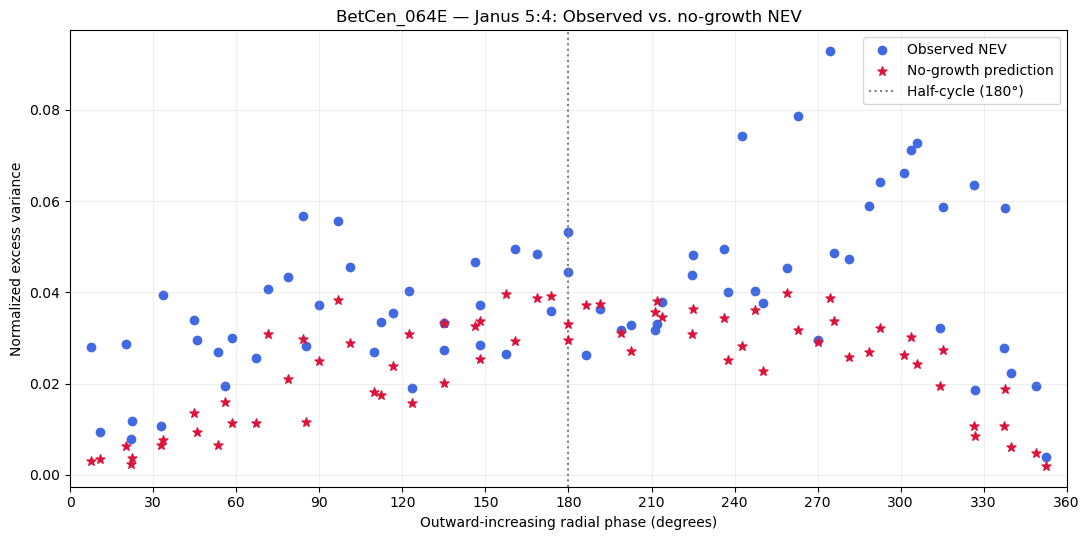

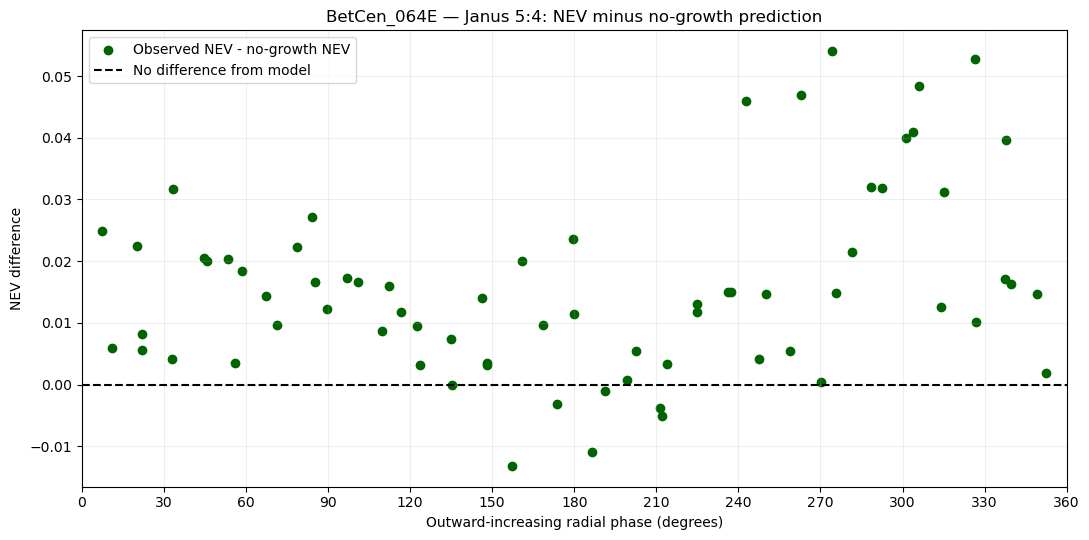

In [86]:

# ============================================================
# COMPARE OBSERVED NEV WITH THE NO-GROWTH MODEL
# ============================================================

# Keep only valid data
valid = (
    np.isfinite(ng_phase)
    & np.isfinite(ng_observed)
    & np.isfinite(nev_total)
)

phase = ng_phase[valid]
observed = ng_observed[valid]
predicted = nev_total[valid]

# Difference: observed minus predicted
nev_difference = observed - predicted

# Ratio: observed divided by predicted
# Avoid division by zero or very small model values.
ratio_valid = predicted > 1e-10

ratio_phase = phase[ratio_valid]
nev_ratio = observed[ratio_valid] / predicted[ratio_valid]

# ------------------------------------------------------------
# Plot 1: Observed NEV vs. no-growth prediction
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 5.5))

ax.scatter(
    phase, observed,
    color="royalblue",
    label="Observed NEV"
)

ax.scatter(
    phase, predicted,
    color="crimson",
    marker="*",
    s=45,
    label="No-growth prediction",
    zorder=4
)

ax.axvline(
    180, color="gray", linestyle=":",
    label="Half-cycle (180°)"
)

ax.set(
    xlabel="Outward-increasing radial phase (degrees)",
    ylabel="Normalized excess variance",
    title=f"{occstring} — {wave_str}: Observed vs. no-growth NEV",
    xlim=(0, 360)
)

ax.set_xticks(np.arange(0, 361, 30))
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()
plt.close(fig)


# ------------------------------------------------------------
# Plot 2: NEV difference (observed - no-growth)
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 5.5))

ax.scatter(
    phase, nev_difference,
    color="darkgreen",
    label="Observed NEV - no-growth NEV"
)

ax.axhline(
    0, color="black", linestyle="--",
    label="No difference from model"
)

ax.set(
    xlabel="Outward-increasing radial phase (degrees)",
    ylabel="NEV difference",
    title=f"{occstring} — {wave_str}: NEV minus no-growth prediction",
    xlim=(0, 360)
)

ax.set_xticks(np.arange(0, 361, 30))
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()
plt.close(fig)

## 11. Fit a sinusoid to the NEV difference

Fit the same first-order sinusoid to **observed NEV − no-growth NEV**, rather than to the raw NEV. This asks where the *model discrepancy* has its strongest first-harmonic modulation. Estimate approximate 95% bootstrap intervals for amplitude and crest-referenced lag and compare the fitted maximum with the **approximately 300° radial phase** associated with the predator–prey prediction. The no-growth model is held fixed in this uncertainty calculation.


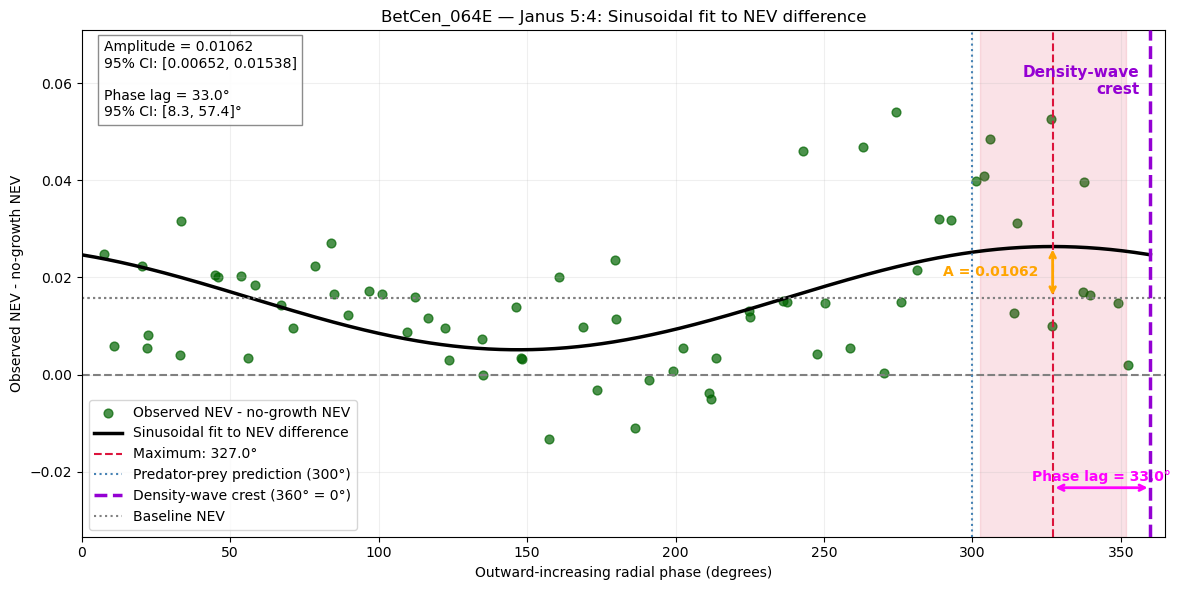

Difference-fit radial maximum: 327.0°
Difference-fit phase lag: 33.0°
Difference-fit amplitude: 0.01062


In [87]:

# ============================================================
# SINUSOID FIT: OBSERVED NEV MINUS NO-GROWTH NEV
# ============================================================

# Explicitly calculate the difference
diff_phase = np.asarray(phase, dtype=float)
diff_nev = np.asarray(observed - predicted, dtype=float)

# Match cycle labels to the filtered phase bins
diff_cycles = np.asarray(cycle_first)[valid]

# Fit sinusoid to the DIFFERENCE
diff_fit = fit_sinusoid(diff_phase, diff_nev)

theta = np.deg2rad(diff_phase)
diff_prediction = (
    diff_fit["C"]
    + diff_fit["a"] * np.cos(theta)
    + diff_fit["b"] * np.sin(theta)
)

# ------------------------------------------------------------
# Bootstrap confidence intervals
# ------------------------------------------------------------

rng = np.random.default_rng(2026)
n_boot = 2000

boot_A = []
boot_phase = []

for _ in range(n_boot):
    synthetic = diff_prediction.copy()

    for cycle in np.unique(diff_cycles):
        idx = np.where(diff_cycles == cycle)[0]
        residuals = diff_nev[idx] - diff_prediction[idx]
        residuals -= residuals.mean()

        synthetic[idx] += moving_block_resample(
            residuals, min(3, len(residuals)), rng
        )

    boot = fit_sinusoid(diff_phase, synthetic)
    boot_A.append(boot["A"])
    boot_phase.append(boot["phase_max"])

A_ci = np.percentile(boot_A, [2.5, 97.5])
phase_delta = circular_difference(
    np.asarray(boot_phase), diff_fit["phase_max"]
)
phase_ci_delta = np.percentile(phase_delta, [2.5, 97.5])

lag_ci = (
    diff_fit["crest_offset"] - phase_ci_delta[::-1]
) % 360

# ------------------------------------------------------------
# Plot fitted difference
# ------------------------------------------------------------

x = np.linspace(0, 360, 1000)
y = (
    diff_fit["C"]
    + diff_fit["a"] * np.cos(np.deg2rad(x))
    + diff_fit["b"] * np.sin(np.deg2rad(x))
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.scatter(
    diff_phase, diff_nev,
    color="darkgreen", s=40, alpha=0.7,
    label="Observed NEV - no-growth NEV"
)

ax.plot(
    x, y, color="black", lw=2.5,
    label="Sinusoidal fit to NEV difference"
)

ax.axhline(0, color="gray", linestyle="--")
ax.axhline(diff_fit["C"], color="gray", linestyle=":")

ax.axvline(
    diff_fit["phase_max"], color="crimson",
    linestyle="--",
    label=f"Maximum: {diff_fit['phase_max']:.1f}°"
)

ax.axvline(
    300, color="steelblue", linestyle=":",
    label="Predator-prey prediction (300°)"
)

# Density-wave crest at 360 degrees (= 0 degrees)
ax.axvline(
    360,
    color="darkviolet",
    linestyle="--",
    linewidth=2.5,
    zorder=5,
    label="Density-wave crest (360° = 0°)"
)

# Add a label above the crest line
ax.annotate(
    "Density-wave\ncrest",
    xy=(360, 0.90),
    xycoords=("data", "axes fraction"),
    xytext=(-8, 0),
    textcoords="offset points",
    ha="right",
    va="center",
    fontsize=11,
    fontweight="bold",
    color="darkviolet"
)
# Shade phase CI, including wraparound at 0/360
bounds = diff_fit["phase_max"] + phase_ci_delta
if bounds[1] - bounds[0] < 180:
    for shift in (-360, 0, 360):
        left = max(0, bounds[0] + shift)
        right = min(360, bounds[1] + shift)
        if right > left:
            ax.axvspan(left, right, color="crimson", alpha=0.12)

# Amplitude arrow
peak = diff_fit["phase_max"]
baseline = diff_fit["C"]
amplitude = diff_fit["A"]

ax.annotate(
    "", xy=(peak, baseline + amplitude),
    xytext=(peak, baseline),
    arrowprops=dict(arrowstyle="<->", color="orange", lw=2)
)

ax.text(
    peak - 5, baseline + amplitude/2,
    f"A = {amplitude:.5f}",
    ha="right", va="center", color="orange", fontweight="bold"
)

ax.axhline(
    diff_fit["C"],
    color="gray", linestyle=":",
    label="Baseline NEV"
)

# Phase-lag arrow
ymin, ymax = min(diff_nev.min(), y.min()), max(diff_nev.max(), y.max())
span = ymax - ymin
ax.set_ylim(ymin - 0.30*span, ymax + 0.25*span)

arrow_y = ymin - 0.15*span
ax.annotate(
    "", xy=(360, arrow_y), xytext=(peak, arrow_y),
    arrowprops=dict(arrowstyle="<->", color="magenta", lw=2)
)

ax.text(
    (peak + 360)/2, arrow_y + 0.02*span,
    f"Phase lag = {diff_fit['crest_offset']:.1f}°",
    ha="center", color="magenta", fontweight="bold"
)

# Numerical results and confidence intervals
summary = (
    f"Amplitude = {amplitude:.5f}\n"
    f"95% CI: [{A_ci[0]:.5f}, {A_ci[1]:.5f}]\n\n"
    f"Phase lag = {diff_fit['crest_offset']:.1f}°\n"
    f"95% CI: [{lag_ci[0]:.1f}, {lag_ci[1]:.1f}]°"
)

ax.text(
    0.02, 0.98, summary,
    transform=ax.transAxes, va="top",
    bbox=dict(facecolor="white", edgecolor="gray", alpha=0.9)
)

ax.set(
    xlabel="Outward-increasing radial phase (degrees)",
    ylabel="Observed NEV - no-growth NEV",
    title=f"{occstring} — {wave_str}: Sinusoidal fit to NEV difference",
    xlim=(0, 365)
)

ax.grid(alpha=0.2)
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()
plt.close(fig)

print(f"Difference-fit radial maximum: {peak:.1f}°")
print(f"Difference-fit phase lag: {diff_fit['crest_offset']:.1f}°")
print(f"Difference-fit amplitude: {amplitude:.5f}")

## 12. Test the stability of the NEV-difference maximum

Leave out each density-wave cycle in turn and refit the sinusoid to the NEV difference. Compare the maximum, lag, and amplitude with the full-data fit. **Why:** this checks whether the apparent phase of the discrepancy persists across the observed cycles, rather than being set by a single interval.


In [88]:

# ============================================================
# LEAVE-ONE-CYCLE-OUT TEST: NEV MINUS NO-GROWTH
# ============================================================

print("Leave-one-cycle-out sensitivity test")
print("NEV difference = Observed NEV - No-growth NEV")
print()

full_phase = diff_fit["phase_max"]
full_lag = diff_fit["crest_offset"]
full_amplitude = diff_fit["A"]

print(f"All-data radial maximum: {full_phase:.1f}°")
print(f"All-data phase lag:      {full_lag:.1f}°")
print(f"All-data amplitude:      {full_amplitude:.5f}")
print()

print(
    f"{'Excluded cycle':>14} | "
    f"{'Radial maximum':>15} | "
    f"{'Phase lag':>10} | "
    f"{'Amplitude':>10} | "
    f"{'Phase shift':>12}"
)
print("-" * 78)

loo_results = []

for cycle in np.unique(diff_cycles):

    # Keep all measurements except this cycle
    keep = diff_cycles != cycle

    # Refit sinusoid to remaining cycles
    loo_fit = fit_sinusoid(
        diff_phase[keep],
        diff_nev[keep]
    )

    loo_phase = loo_fit["phase_max"]
    loo_lag = loo_fit["crest_offset"]
    loo_amplitude = loo_fit["A"]

    # Circular difference relative to full-data fit
    phase_shift = (
        (loo_phase - full_phase + 180) % 360
    ) - 180

    loo_results.append({
        "excluded_cycle": cycle,
        "phase_max": loo_phase,
        "phase_lag": loo_lag,
        "amplitude": loo_amplitude,
        "phase_shift": phase_shift
    })

    print(
        f"{int(cycle) + 1:>14} | "
        f"{loo_phase:>14.1f}° | "
        f"{loo_lag:>9.1f}° | "
        f"{loo_amplitude:>10.5f} | "
        f"{phase_shift:>+11.1f}°"
    )

print()
print(
    "Maximum absolute phase shift: "
    f"{max(abs(r['phase_shift']) for r in loo_results):.1f}°"
)


Leave-one-cycle-out sensitivity test
NEV difference = Observed NEV - No-growth NEV

All-data radial maximum: 327.0°
All-data phase lag:      33.0°
All-data amplitude:      0.01062

Excluded cycle |  Radial maximum |  Phase lag |  Amplitude |  Phase shift
------------------------------------------------------------------------------
             1 |          312.1° |      47.9° |    0.01014 |       -14.9°
             2 |          325.2° |      34.8° |    0.01204 |        -1.9°
             3 |          338.4° |      21.6° |    0.01039 |       +11.3°

Maximum absolute phase shift: 14.9°


## Student deliverables

For at least two occultation–wave combinations, complete the following analysis.

1. Density-wave identification and observed NEV

Record the occultation, density wave, selected crest radii, and number of NEV bins. Report the first-order sinusoidal amplitude, radial phase of maximum NEV, crest-referenced phase lag, RMS residual, and 95% bootstrap confidence intervals for amplitude and phase lag.

Include the crest-verification plot and the sinusoidal-fit plot.

2. Comparison with the no-growth model

Generate and include the following plots:

- Observed NEV versus the no-growth prediction.

- Observed NEV minus the no-growth prediction.

For the NEV-minus-no-growth sinusoidal fit, report the fitted amplitude, radial maximum, crest-referenced phase lag, and 95% bootstrap confidence intervals.

3. Sensitivity analysis

Report the leave-one-cycle-out results for both the original NEV fit and the NEV-minus-no-growth fit. Note how much the fitted maximum changes when each density-wave cycle is excluded.

4. Research questions

Briefly address the following questions:

- Do the observed NEV maxima occur at similar phases for the different occultation–wave combinations?

- Does subtracting the no-growth prediction change the fitted maximum? If so, by how much?

- Are the results consistent with the approximately 60° phase lag predicted by the predator–prey model (corresponding to a radial maximum near 300°)?

- How sensitive are your conclusions to the exclusion of individual density-wave cycles?

**Limitations**: The first-harmonic maximum is not necessarily the true maximum of an asymmetric or double-peaked NEV distribution. The fits are unweighted, neighboring measurements may be correlated, and the bootstrap confidence intervals are approximate and model-dependent. The no-growth model parameters are assumed fixed, and its predictions depend on the measured optical depths. Leave-one-cycle-out results are sensitivity checks, not formal confidence intervals. The wave-region ranges and no-growth model parameters must be verified for each density wave before interpreting the results.
